# Interesting-genes heatmap — organoid Cd vs Mock across butyrate dose
### Reproduces the co-colonization 'Pathway response' heatmap, now on organoid data (for Sara/Alex/Franzi)

Matches the reference figure exactly: **log2FC (Cd vs Mock)**, diverging blue-red centred at 0,
`*` for padj<0.05, grouped gene rows with left-hand group labels.

**Columns** (from Sara's Excel): `Cd 0 / Cd 5 / Cd 10` = log2FC of **Cd vs Mock at 0 / 5 / 10 mM butyrate**
(i.e. Cd 0mM means Cd 0mM vs Mock 0mM). Reads the three organoid DE tables directly.

Gene list & grouping are exactly Sara's layout sheet (typos fixed to official symbols:
MAPKB→MAPK8, NFKB1A→NFKBIA, AFT6→ATF6, AFT4→ATF4).

In [1]:
import pandas as pd, numpy as np, os, re
from pathlib import Path
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
A04 = Path(os.environ.get('A04_PROJ', str(Path.home()/'Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate')))
TAB = A04/'results/tables'; OUT = A04/'results/overview_for_sara'; OUT.mkdir(parents=True, exist_ok=True)
mpl.rcParams.update({'font.family':'sans-serif','font.sans-serif':['Helvetica','Arial','DejaVu Sans'],
  'figure.dpi':130,'savefig.dpi':300,'savefig.bbox':'tight'})

# ---- gene groups exactly as Sara's Excel (order preserved), symbols corrected ----
GROUPS = [
 ('NFkB upstream',      ['NOD2','IRAK2','TRAF6','TAB2','MAPK8','IKBKE']),
 ('NFkB core',          ['NFKB1','RELA','REL','RELB','NFKBIA']),
 ('NFkB output',        ['CXCL1','CXCL2','CXCL8','CCL20','BIRC3','TNFAIP3','PTGS2']),
 ('UPR sensors',        ['EIF2AK3','ATF6','XBP1','ATF4','STAT3']),
 ('ER chaperones',      ['HSPA5','HYOU1','CALR','PDIA3','PDIA4','PDIA6','SDF2L1','WFS1','MANF']),
 ('PPARG / metabolism', ['PPARG','CYLD','TP53','NR3C1','PCK1','CYP11A1']),
 ('AR / non-canon.',    ['AR','GSK3B']),
]
group_colors = {'NFkB upstream':'#c0392b','NFkB core':'#c0392b','NFkB output':'#e74c3c',
 'UPR sensors':'#2980b9','ER chaperones':'#2471a3','PPARG / metabolism':'#27ae60','AR / non-canon.':'#8e44ad'}

In [2]:
def load_de(fname):
    d=pd.read_csv(TAB/fname,index_col=0)
    for col in ['gene_name','symbol','Gene','gene']:
        if col in d.columns: d=d.set_index(col); break
    d.index=[re.sub(r'\..*','',str(i)) for i in d.index]
    if d.index.duplicated().any():
        pcol='padj' if 'padj' in d.columns else 'pvalue'
        d=d.assign(_p=d[pcol].fillna(1)).sort_values('_p').loc[~d.index.duplicated(keep='first')].drop(columns='_p')
    return d
cols=[('DE_Cd_vs_Mock_0mM.csv','Cd 0'),('DE_Cd_vs_Mock_5mM.csv','Cd 5'),('DE_Cd_vs_Mock_10mM.csv','Cd 10')]
LFC={}; PADJ={}
for fn,lab in cols:
    d=load_de(fn)
    LFC[lab]=d['log2FoldChange'] if 'log2FoldChange' in d.columns else d.get('log2FC')
    PADJ[lab]=d['padj'] if 'padj' in d.columns else d.get('pvalue')
LFC=pd.DataFrame(LFC); PADJ=pd.DataFrame(PADJ)

# assemble in Sara's row order; keep missing as NaN (drawn blank) but report them
rows=[]; row_genes=[]; row_group=[]; missing=[]
for gname,genes in GROUPS:
    for g in genes:
        row_genes.append(g); row_group.append(gname)
        if g in LFC.index: rows.append(LFC.loc[g].values)
        else: rows.append([np.nan]*len(cols)); missing.append(g)
M=pd.DataFrame(rows, index=row_genes, columns=[l for _,l in cols])
P=pd.DataFrame([(PADJ.loc[g].values if g in PADJ.index else [np.nan]*len(cols)) for g in row_genes],
               index=row_genes, columns=M.columns)
print('genes:',len(M),'| missing in organoid data:', missing)

genes: 40 | missing in organoid data: ['PTGS2', 'CYP11A1', 'AR']


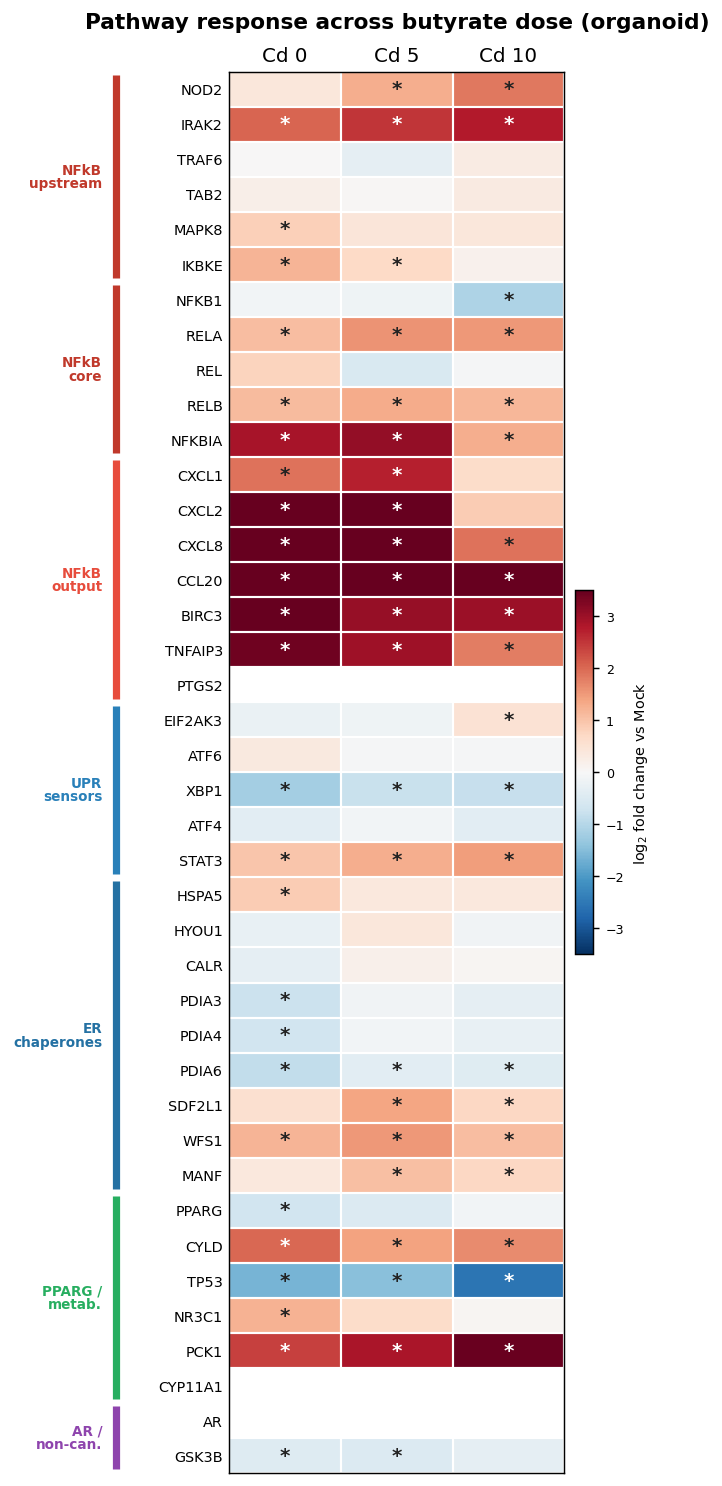

wrote /home/job37yv/Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate/results/overview_for_sara/heatmap_interesting_genes_organoid_Cd_vs_Mock.png


In [9]:
# ---- heatmap: diverging blue-red centred at 0, * for padj<0.05, group labels on left ----
vmax=float(np.nanmax(np.abs(M.values))); vmax=max(1.0, min(vmax,3.5))
norm=TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)
n=len(M); ncol=M.shape[1]
fig,ax=plt.subplots(figsize=(5.6, 0.32*n+1.2))          # wider for label room
im=ax.imshow(M.values, cmap='RdBu_r', norm=norm, aspect='auto')
ax.set_xticks(range(ncol)); ax.set_xticklabels(M.columns, fontsize=11)
ax.xaxis.set_ticks_position('top'); ax.xaxis.set_label_position('top')
ax.set_yticks(range(n)); ax.set_yticklabels(M.index, fontsize=8)
ax.set_xticks(np.arange(-.5,ncol,1),minor=True); ax.set_yticks(np.arange(-.5,n,1),minor=True)
ax.grid(which='minor',color='white',lw=1.2); ax.tick_params(which='minor',length=0); ax.tick_params(which='major',length=0)
# significance *
for i in range(n):
    for j in range(ncol):
        p=P.values[i,j]
        if not pd.isna(p) and p<0.05:
            ax.text(j,i,'*',ha='center',va='center',fontsize=11,fontweight='bold',
                    color='white' if abs(M.values[i,j])>vmax*0.55 else '#222')
# group brackets + labels on the left
ax.set_title('Pathway response across butyrate dose (organoid)', fontsize=12, fontweight='bold', pad=24)
fig.subplots_adjust(left=0.40)                     # more left room
from matplotlib.transforms import blended_transform_factory
tf = blended_transform_factory(ax.transAxes, ax.transData)
X_BRACKET = -0.34
X_LABEL   = -0.38
# short, wrapped labels so long ones don't run into the next group
LABEL_TEXT = {
    'NFkB upstream':'NFkB\nupstream',
    'NFkB core':'NFkB\ncore',
    'NFkB output':'NFkB\noutput',
    'UPR sensors':'UPR\nsensors',
    'ER chaperones':'ER\nchaperones',
    'PPARG / metabolism':'PPARG /\nmetab.',
    'AR / non-canon.':'AR /\nnon-can.',
}
start=0
for gname,genes in GROUPS:
    end=start+len(genes)
    # bracket
    ax.plot([X_BRACKET, X_BRACKET],[start-0.4, end-0.6], color=group_colors[gname], lw=4,
            transform=tf, clip_on=False, solid_capstyle='butt')
    # horizontal (not rotated) wrapped label, centered on the bracket
    ax.text(X_LABEL, (start+end-1)/2, LABEL_TEXT.get(gname, gname), rotation=0,
            va='center', ha='right', fontsize=7.5, linespacing=0.95,
            color=group_colors[gname], fontweight='bold', transform=tf, clip_on=False)
    start=end
cb=fig.colorbar(im,ax=ax,fraction=0.05,pad=0.03); cb.set_label('log$_2$ fold change vs Mock',fontsize=8); cb.ax.tick_params(labelsize=7)
fig.savefig(OUT/'heatmap_interesting_genes_organoid_Cd_vs_Mock.png', bbox_inches='tight')
plt.show()
print('wrote', OUT/'heatmap_interesting_genes_organoid_Cd_vs_Mock.png')

In [4]:
# ---- export underlying data (log2FC + padj per gene per dose) ----
exp=M.copy(); exp.columns=[c2+' log2FC' for c2 in exp.columns]
for lab in M.columns: exp[lab+' padj']=P[lab]
exp.insert(0,'group',row_group); exp.index.name='gene'
csv=OUT/'heatmap_interesting_genes_organoid_Cd_vs_Mock.csv'; exp.round(4).to_csv(csv)
print('wrote',csv); print(exp.round(3).head(12))

wrote /home/job37yv/Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate/results/overview_for_sara/heatmap_interesting_genes_organoid_Cd_vs_Mock.csv
                group  Cd 0 log2FC  Cd 5 log2FC  Cd 10 log2FC  Cd 0 padj  \
gene                                                                       
NOD2    NFkB upstream        0.395        1.267         1.848      0.246   
IRAK2   NFkB upstream        2.034        2.503         2.786      0.000   
TRAF6   NFkB upstream        0.003       -0.320         0.288      0.993   
TAB2    NFkB upstream        0.213        0.029         0.307      0.331   
MAPK8   NFkB upstream        0.839        0.413         0.385      0.001   
IKBKE   NFkB upstream        1.188        0.709         0.159      0.000   
NFKB1       NFkB core       -0.082       -0.142        -1.070      0.802   
RELA        NFkB core        1.075        1.581         1.523      0.000   
REL         NFkB core        0.767       -0.542        -0.048      0.090   
RELB        NFkB c

## Notes for Sara / Alex / Franzi
- **Exactly the co-colonization layout**, now on organoid data. Columns are Cd-vs-Mock log2FC at
  0 / 5 / 10 mM butyrate (Cd0 = Cd 0mM vs Mock 0mM), grouped and ordered per the Excel.
- Diverging blue-red centred at 0 (blue = down vs Mock, red = up); `*` = padj<0.05 — same convention
  as the reference figure. (This is the signed version; the earlier `_reds` one clipped negatives to 0.)
- Gene-symbol typos in the sheet were corrected: MAPKB→MAPK8, NFKB1A→NFKBIA, AFT6→ATF6, AFT4→ATF4.
- `missing` (printed above) = genes not detected in the organoid annotation; shown as blank cells.
- Underlying log2FC + padj exported as CSV alongside.